In [1]:
# CELL 1 — SETTINGS AND DATASET DISCOVERY
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = None  # e.g., '/content/all_seasons.csv' or '/content/drive/MyDrive/NBA/all_seasons.csv'
MIN_GP = 20                 # use recorded games for leaderboard eligibility
MVP_MIN_GP = 40             # exploratory MVP eligibility, adjust only with explanation
TARGET_SEASON = None       # e.g., '2022-23'; None = latest available season
SAVE_DIR = Path('/content/NBA_Project6_Outputs')
SAVE_DIR.mkdir(exist_ok=True, parents=True)

if DATA_FILE is None:
    candidates = [p for p in Path('/content').rglob('*')
                  if p.is_file() and p.suffix.lower() in ('.csv','.parquet','.xlsx')
                  and 'NBA_Project6_Outputs' not in str(p)
                  and '.ipynb_checkpoints' not in str(p)]
    candidates = sorted(candidates, key=lambda p:(p.suffix.lower() != '.csv', str(p)))
    print('Found candidate data files:')
    for p in candidates[:20]: print(' •',p)
    if len(candidates)==0:
        raise FileNotFoundError('Upload your dataset to Colab Files, or set DATA_FILE to a Google Drive path.')
    if len(candidates)>1:
        print('Multiple files found; set DATA_FILE to the intended NBA dataset if the first one is not correct.')
    DATA_FILE=str(candidates[0])

path=Path(DATA_FILE)
if not path.exists():
    raise FileNotFoundError(f'{path} not found. Files uploaded to Colab may disappear after a runtime reset.')
if path.suffix.lower()=='.csv':
    raw=pd.read_csv(path, low_memory=False)
elif path.suffix.lower()=='.parquet':
    raw=pd.read_parquet(path)
elif path.suffix.lower()=='.xlsx':
    raw=pd.read_excel(path)
else: raise ValueError('Supported formats: CSV, Parquet, Excel')
raw.columns=[str(c).strip().lower().replace(' ','_') for c in raw.columns]
print(f'Loaded {path.name}: {len(raw):,} rows; {len(raw.columns)} columns')
print('Columns:', raw.columns.tolist())
display(raw.head(4))
print('\nMissing data by column (top 20):')
display(raw.isna().sum().sort_values(ascending=False).head(20).to_frame('nulls'))

Found candidate data files:
 • /content/all_seasons.csv
 • /content/sample_data/california_housing_test.csv
 • /content/sample_data/california_housing_train.csv
 • /content/sample_data/mnist_test.csv
 • /content/sample_data/mnist_train_small.csv
Multiple files found; set DATA_FILE to the intended NBA dataset if the first one is not correct.
Loaded all_seasons.csv: 12,844 rows; 22 columns
Columns: ['unnamed:_0', 'player_name', 'team_abbreviation', 'age', 'player_height', 'player_weight', 'college', 'country', 'draft_year', 'draft_round', 'draft_number', 'gp', 'pts', 'reb', 'ast', 'net_rating', 'oreb_pct', 'dreb_pct', 'usg_pct', 'ts_pct', 'ast_pct', 'season']


,unnamed:_0,player_name,team_abbreviation,age,player_height,player_weight,college,country,draft_year,draft_round,...,pts,reb,ast,net_rating,oreb_pct,dreb_pct,usg_pct,ts_pct,ast_pct,season
0,0,Randy Livingston,HOU,22.0,193.04,94.800728,Louisiana State,USA,1996,2,...,3.9,1.5,2.4,0.3,0.042,0.071,0.169,0.487,0.248,1996-97
1,1,Gaylon Nickerson,WAS,28.0,190.50,86.182480,Northwestern Oklahoma,USA,1994,2,...,3.8,1.3,0.3,8.9,0.030,0.111,0.174,0.497,0.043,1996-97
2,2,George Lynch,VAN,26.0,203.20,103.418976,North Carolina,USA,1993,1,...,8.3,6.4,1.9,-8.2,0.106,0.185,0.175,0.512,0.125,1996-97
3,3,George McCloud,LAL,30.0,203.20,102.058200,Florida State,USA,1989,1,...,10.2,2.8,1.7,-2.7,0.027,0.111,0.206,0.527,0.125,1996-97



Missing data by column (top 20):


,nulls
college,1854
unnamed:_0,0
team_abbreviation,0
age,0
player_height,0
player_name,0
player_weight,0
country,0
draft_year,0
draft_round,0


In [2]:
# CELL 2 — STANDARDIZE FIELDS & AUDIT DATA GRAIN
aliases={
 'player':['player_name','player','name'], 'season':['season','year','season_year'],
 'team':['team_abbreviation','team','tm'], 'position':['position','pos'],
 'points':['pts','ppg','points_per_game'], 'rebounds':['reb','rpg','rebounds_per_game'],
 'assists':['ast','apg','assists_per_game'], 'games':['gp','games_played','g'],
 'ts':['ts_pct','true_shooting_percentage','ts%'],
 'usage':['usg_pct','usage_percentage','usg%','usg'],
 'height':['player_height','height_cm','height'],
 'weight':['player_weight','weight_kg','weight'],
 'age':['age','player_age'], 'draft_year':['draft_year'],
 'draft_number':['draft_number','draft_pick'],
}
mapcols={k:next((v for v in vals if v in raw.columns),None) for k,vals in aliases.items()}
print('Detected fields:'); display(pd.Series(mapcols,name='source_column').to_frame())
required=['player','season','points','rebounds','assists']
missing=[c for c in required if mapcols[c] is None]
if missing: raise ValueError(f'Missing required concepts: {missing}. Check actual dataset column names and update aliases.')

D=pd.DataFrame(index=raw.index)
for name,col in mapcols.items():
    D[name]=raw[col] if col else np.nan
for c in ['points','rebounds','assists','games','ts','usage','height','weight','age','draft_year','draft_number']:
    D[c]=pd.to_numeric(D[c],errors='coerce')
for c in ['player','season','team','position']:
    D[c]=D[c].astype('string').str.strip()
D['season_start']=pd.to_numeric(D['season'].str.extract(r'(\d{4})')[0],errors='coerce')
D['era']=pd.cut(D['season_start'],[1989,1999,2009,2019,2029],labels=['1990s','2000s','2010s','2020s'])
D['ts_display_pct']=np.where(D['ts']<=1,D['ts']*100,D['ts'])
D['usage_display_pct']=np.where(D['usage']<=1,D['usage']*100,D['usage'])
D['total_per_game']=D[['points','rebounds','assists']].sum(axis=1,min_count=3)

print('Rows before cleaning:',len(D))
print('Rows missing player/season:',int(D[['player','season']].isna().any(axis=1).sum()))
print('Exact duplicate source rows:',int(raw.duplicated().sum()))
print('Repeated player+season keys:',int(D.duplicated(['player','season']).sum()))
print('Repeated player+season+team keys:',int(D.duplicated(['player','season','team']).sum()))
print('Seasons:',D['season_start'].min(),'to',D['season_start'].max())
print('Available position data:',int(D['position'].notna().sum()),'rows')

# Repeated player-seasons may indicate traded-player team splits or true source duplication.
# Do not arbitrarily aggregate per-game rates or pick a favorite team.
conflicts=D[D.duplicated(['player','season'],keep=False)].sort_values(['player','season'])
if len(conflicts):
    conflicts.to_csv(SAVE_DIR/'player_season_duplicate_keys_AUDIT.csv',index=False)
    print('ATTENTION: repeated player-season keys detected. Review audit CSV; rankings will use one unambiguous row per player-season only.')

valid=D.dropna(subset=['player','season','points','rebounds','assists']).copy()
valid=valid[valid['season_start'].notna()]
# Keep only player-seasons represented by exactly one record, preventing false merging.
keysize=valid.groupby(['player','season'])['player'].transform('size')
excluded_repeated=int((keysize>1).sum())
valid=valid[keysize==1].copy()
print('Unambiguous player-seasons used:',len(valid),'; repeated-key rows excluded:',excluded_repeated)
assert len(valid)>0, 'No unambiguous player-season rows remain. Investigate repeated keys before analysis.'
valid.to_csv(SAVE_DIR/'player_seasons_clean.csv',index=False)

Detected fields:


,source_column
player,player_name
season,season
team,team_abbreviation
position,None
points,pts
rebounds,reb
assists,ast
games,gp
ts,ts_pct
usage,usg_pct


Rows before cleaning: 12844
Rows missing player/season: 0
Exact duplicate source rows: 0
Repeated player+season keys: 4
Repeated player+season+team keys: 0
Seasons: 1996 to 2022
Available position data: 0 rows
ATTENTION: repeated player-season keys detected. Review audit CSV; rankings will use one unambiguous row per player-season only.
Unambiguous player-seasons used: 12836 ; repeated-key rows excluded: 8


In [3]:
# CELL 3 — SEASON LEADERS, EFFICIENCY, AND MOST IMPROVED
eligible=valid.copy()
if eligible['games'].notna().any():
    eligible=eligible[(eligible['games']>=MIN_GP) & eligible['games'].notna()].copy()
else:
    print('Games played unavailable: cannot enforce minimum games; leaderboards are provisional.')

leaderboards=[]
for metric in ['points','rebounds','assists']:
    part=eligible.sort_values(['season_start',metric,'player'],ascending=[True,False,True]).copy()
    part['metric']=metric
    part['metric_value']=part[metric]
    part['rank']=part.groupby('season')[metric].rank(method='min',ascending=False)
    leaderboards.append(part.loc[part['rank']<=10,['season','season_start','player','team','games','metric','metric_value','rank','ts_display_pct','usage_display_pct']])
leaders=pd.concat(leaderboards,ignore_index=True)
leaders.to_csv(SAVE_DIR/'season_top10_leaderboards.csv',index=False)
print('Latest season top performers:')
latest=valid['season_start'].max()
display(leaders[(leaders.season_start==latest)&(leaders['rank']<=5)].sort_values(['metric','rank']))

if valid['ts_display_pct'].notna().any() and valid['usage_display_pct'].notna().any():
    efficiency=eligible.dropna(subset=['ts_display_pct','usage_display_pct']).copy()
    print('Overall usage vs true shooting correlation (descriptive):',round(efficiency['usage_display_pct'].corr(efficiency['ts_display_pct']),3))
    efficiency.to_csv(SAVE_DIR/'usage_vs_efficiency.csv',index=False)
else:
    efficiency=pd.DataFrame()
    print('TS% and/or usage% missing: efficiency comparison skipped.')

improved=valid.sort_values(['player','season_start']).copy()
improved['previous_season']=improved.groupby('player')['season_start'].shift(1)
improved['consecutive']=improved['season_start'].eq(improved['previous_season']+1)
for stat in ['points','rebounds','assists']:
    improved[f'{stat}_change']=improved.groupby('player')[stat].diff().where(improved['consecutive'])
improved=improved[improved['consecutive']].copy()
improved['improvement_index']=improved[['points_change','rebounds_change','assists_change']].sum(axis=1,min_count=3)
improved.sort_values('improvement_index',ascending=False).to_csv(SAVE_DIR/'year_over_year_improvement.csv',index=False)
print('Largest consecutive-season increases in PPG + RPG + APG (exploratory):')
display(improved[['player','season','previous_season','points_change','rebounds_change','assists_change','improvement_index']].sort_values('improvement_index',ascending=False).head(10))

Latest season top performers:


,season,season_start,player,team,games,metric,metric_value,rank,ts_display_pct,usage_display_pct
813,2022-23,2022,James Harden,PHI,58,assists,10.7,1.0,60.7,24.7
814,2022-23,2022,Tyrese Haliburton,IND,56,assists,10.4,2.0,62.4,23.8
815,2022-23,2022,Trae Young,ATL,73,assists,10.2,3.0,57.3,31.3
816,2022-23,2022,Nikola Jokic,DEN,69,assists,9.8,4.0,70.1,26.3
817,2022-23,2022,Chris Paul,PHX,59,assists,8.9,5.0,55.5,19.5
263,2022-23,2022,Joel Embiid,PHI,66,points,33.1,1.0,65.5,37.0
264,2022-23,2022,Luka Doncic,DAL,66,points,32.4,2.0,60.9,36.8
265,2022-23,2022,Damian Lillard,POR,58,points,32.2,3.0,64.5,33.1
266,2022-23,2022,Shai Gilgeous-Alexander,OKC,68,points,31.4,4.0,62.6,31.8
267,2022-23,2022,Giannis Antetokounmpo,MIL,63,points,31.1,5.0,60.5,37.3


Overall usage vs true shooting correlation (descriptive): 0.088
Largest consecutive-season increases in PPG + RPG + APG (exploratory):


,player,season,previous_season,points_change,rebounds_change,assists_change,improvement_index
12438,Skylar Mays,2022-23,2021,12.4,2.3,7.7,22.4
11576,Khyri Thomas,2020-21,2019,14.3,3.5,4.6,22.4
8996,Julius Randle,2015-16,2014,9.3,10.2,1.8,21.3
3551,Ndudi Ebi,2004-05,2003,12.7,7.8,0.3,20.8
8876,Paul George,2015-16,2014,14.3,3.3,3.1,20.7
10213,JaKarr Sampson,2018-19,2017,15.3,4.5,0.6,20.4
4612,Nene,2006-07,2005,12.2,7.0,1.2,20.4
10888,Devonte' Graham,2019-20,2018,13.5,2.0,4.9,20.4
12748,Louis King,2022-23,2021,15.5,2.8,1.1,19.4
3361,Zach Randolph,2003-04,2002,11.7,6.0,1.5,19.2


In [4]:
# CELL 4 — ERA, TEAM, ROOKIE VS VETERAN
by_era=valid.dropna(subset=['era']).groupby('era',observed=True).agg(
    player_seasons=('player','size'),players=('player','nunique'),
    mean_height=('height','mean'),mean_weight=('weight','mean'),
    mean_ppg=('points','mean'),mean_rpg=('rebounds','mean'),mean_apg=('assists','mean'),
    mean_ts_pct=('ts_display_pct','mean'),mean_usage_pct=('usage_display_pct','mean')
).reset_index()
by_era.to_csv(SAVE_DIR/'era_comparison.csv',index=False)
display(by_era.round(2))

# Illustrative composite for team-level counts; NOT official MVP metric.
scored=eligible.copy()
for stat in ['points','rebounds','assists']:
    scored[stat+'_percentile']=scored.groupby('season')[stat].rank(pct=True)
scored['basic_performance_index']=(scored['points_percentile']*0.5+scored['rebounds_percentile']*0.25+scored['assists_percentile']*0.25)
scored['season_top10']=scored.groupby('season')['basic_performance_index'].rank(ascending=False,method='min')<=10
if scored['team'].notna().any():
    teams=scored.groupby('team',dropna=True).agg(top10_player_seasons=('season_top10','sum'),tracked_player_seasons=('player','size'),seasons_present=('season','nunique')).reset_index()
    teams['top10_rate']=teams['top10_player_seasons']/teams['tracked_player_seasons']
    teams=teams.sort_values(['top10_player_seasons','top10_rate'],ascending=False)
    teams.to_csv(SAVE_DIR/'team_top_performer_frequency.csv',index=False)
    print('Teams with most top-10 composite player-seasons (not adjusted for roster size):');display(teams.head(12))
else: print('No team data: team analysis skipped.')

if valid['draft_year'].notna().any():
    careers=valid.copy()
    # NBA season start vs draft year is an approximation. Rookie indicator validated as proxy only.
    careers['experience_proxy']=careers['season_start']-careers['draft_year']
    careers['career_stage_proxy']=np.select(
        [(careers['experience_proxy']==0).fillna(False).to_numpy(dtype=bool),
         (careers['experience_proxy']>=5).fillna(False).to_numpy(dtype=bool)],
        ['Draft-year entrant','5+ years since draft'],default='Other/unknown'
    )
    careers.loc[careers.experience_proxy.isna() | (careers.experience_proxy<0),'career_stage_proxy']='Unknown'
    stage=careers.groupby('career_stage_proxy').agg(player_seasons=('player','size'),mean_ppg=('points','mean'),mean_rpg=('rebounds','mean'),mean_apg=('assists','mean')).reset_index()
    stage.to_csv(SAVE_DIR/'draft_year_experience_proxy.csv',index=False)
    print('Draft-year entrants vs veterans (proxy, not verified rookie status):');display(stage.round(2))
else:print('No draft year field: rookie vs veteran comparison skipped.')

,era,player_seasons,players,mean_height,mean_weight,mean_ppg,mean_rpg,mean_apg,mean_ts_pct,mean_usage_pct
0,1990s,1757,665,200.86,100.54,7.83,3.53,1.79,49.25,18.83
1,2000s,4465,1078,201.04,101.37,8.11,3.59,1.78,50.18,18.63
2,2010s,4930,1302,200.60,100.02,8.27,3.55,1.83,51.78,18.40
3,2020s,1684,792,198.82,97.78,8.75,3.54,1.97,54.08,17.80


Teams with most top-10 composite player-seasons (not adjusted for roster size):


,team,top10_player_seasons,tracked_player_seasons,seasons_present,top10_rate
14,LAL,33,365,27,0.090411
11,HOU,19,352,27,0.053977
24,OKC,17,204,15,0.083333
18,MIN,17,363,27,0.046832
7,DAL,12,369,27,0.032520
16,MIA,11,350,27,0.031429
6,CLE,11,373,27,0.029491
29,SAC,10,352,27,0.028409
33,UTA,10,357,27,0.028011
8,DEN,10,361,27,0.027701


Draft-year entrants vs veterans (proxy, not verified rookie status):


,career_stage_proxy,player_seasons,mean_ppg,mean_rpg,mean_apg
0,5+ years since draft,5194,9.82,4.18,2.23
1,Draft-year entrant,1224,5.68,2.59,1.21
2,Other/unknown,4061,8.92,3.80,1.83
3,Unknown,2357,4.78,2.28,1.24


In [5]:
# CELL 5 — EXPLORATORY DATA MVP: 40% SCORING, 30% PLAYMAKING/REBOUNDING, 30% EFFICIENCY
# Within-season percentile ranks reduce scale differences but DO NOT adjust for era, defense, team wins, minutes, or injuries.
# For 30% box-score contribution: 15% rebounds + 15% assists; for 30% efficiency: TS%.
# This is a subjective editorial model, NOT the NBA's official MVP selection process.
season_mvp=valid.copy()
if valid['games'].notna().any():
    season_mvp=season_mvp[season_mvp['games']>=MVP_MIN_GP].copy()
else: print('MVP games threshold could not be applied: GP missing.')
if season_mvp['ts_display_pct'].notna().sum()==0:
    print('WARNING: TS% unavailable; cannot compute the requested efficiency-inclusive Data MVP. Skipping.')
    ranked_mvp=pd.DataFrame()
else:
    season_mvp=season_mvp.dropna(subset=['points','rebounds','assists','ts_display_pct']).copy()
    for stat in ['points','rebounds','assists','ts_display_pct']:
        season_mvp['pct_'+stat]=season_mvp.groupby('season')[stat].rank(pct=True)
    season_mvp['data_mvp_score']=100*(.40*season_mvp['pct_points']+.15*season_mvp['pct_rebounds']+.15*season_mvp['pct_assists']+.30*season_mvp['pct_ts_display_pct'])
    season_mvp['mvp_rank']=season_mvp.groupby('season')['data_mvp_score'].rank(method='min',ascending=False)
    ranked_mvp=season_mvp.sort_values(['season_start','mvp_rank','player'],ascending=[True,True,True])
    ranked_mvp.to_csv(SAVE_DIR/'data_mvp_rankings.csv',index=False)
    chosen=TARGET_SEASON if TARGET_SEASON is not None else ranked_mvp.sort_values('season_start')['season'].iloc[-1]
    print('Selected season:',chosen)
    print('Top 10 Data MVP candidates:')
    display(ranked_mvp[ranked_mvp['season']==chosen][['player','season','team','games','points','rebounds','assists','ts_display_pct','usage_display_pct','data_mvp_score','mvp_rank']].head(10).round(2))
    display(ranked_mvp[ranked_mvp['mvp_rank']==1][['season','player','team','data_mvp_score']].tail(15))

# Optional trustworthy supplements, never invented:
# 1) `official_mvp_awards.csv`: columns season, official_mvp_player
# 2) `player_positions.csv`: columns player, position (PG/SG/SF/PF/C)
awards_path=Path('/content/official_mvp_awards.csv')
if awards_path.exists() and len(ranked_mvp):
    awards=pd.read_csv(awards_path,dtype=str)
    if {'season','official_mvp_player'}.issubset(awards.columns):
        compare=ranked_mvp[ranked_mvp.mvp_rank==1][['season','player','data_mvp_score']].merge(awards[['season','official_mvp_player']],on='season',how='left')
        compare['same_winner']=compare['player'].str.casefold()==compare['official_mvp_player'].str.casefold()
        compare.to_csv(SAVE_DIR/'data_vs_official_mvp.csv',index=False)
        display(compare.tail(15))
    else: print('Official MVP file must contain season and official_mvp_player; comparison skipped.')
else: print('Official NBA MVP comparison requires a verified official_mvp_awards.csv; no winners fabricated.')

position_path=Path('/content/player_positions.csv')
if position_path.exists() and len(ranked_mvp):
    pos=pd.read_csv(position_path,dtype=str)
    pos.columns=pos.columns.str.lower().str.strip()
    if {'player','position'}.issubset(pos):
        pos=pos[['player','position']].drop_duplicates()
        # only uniquely mapped player positions; exclude ambiguous position histories
        unique=pos.groupby('player').filter(lambda g:g['position'].nunique()==1).drop_duplicates('player')
        dream=ranked_mvp.merge(unique,on='player',suffixes=('','_mapped'))
        dream=dream[dream['position_mapped'].isin(['PG','SG','SF','PF','C'])]
        # choose one season performance per candidate, then one player per position
        dream=dream.sort_values('data_mvp_score',ascending=False).drop_duplicates('player')
        dream=dream.sort_values('data_mvp_score',ascending=False).drop_duplicates('position_mapped')
        dream=dream[['position_mapped','player','season','data_mvp_score','points','rebounds','assists','ts_display_pct']].sort_values('position_mapped')
        dream.to_csv(SAVE_DIR/'dream_starting_five_exploratory.csv',index=False)
        print('Exploratory dream five (highest single-season score by validated mapped position):');display(dream)
        if len(dream)<5:print('Incomplete position coverage — fewer than five eligible roles.')
    else: print('Position mapping needs player and position columns.')
else: print('Dream PG/SG/SF/PF/C requires verified player_positions.csv; positions will not be inferred.')

Selected season: 2022-23
Top 10 Data MVP candidates:


,player,season,team,games,points,rebounds,assists,ts_display_pct,usage_display_pct,data_mvp_score,mvp_rank
12381,Nikola Jokic,2022-23,DEN,69,24.5,11.8,9.8,70.1,26.3,96.81,1.0
12839,Joel Embiid,2022-23,PHI,66,33.1,10.2,4.2,65.5,37.0,94.82,2.0
12663,Kevin Durant,2022-23,PHX,47,29.1,6.7,5.0,67.7,30.5,94.04,3.0
12434,Stephen Curry,2022-23,GSW,56,29.4,6.1,6.3,65.6,29.7,93.77,4.0
12564,Damian Lillard,2022-23,POR,58,32.2,4.8,7.3,64.5,33.1,91.79,5.0
12485,Domantas Sabonis,2022-23,SAC,79,19.1,12.3,7.3,66.8,21.3,91.42,6.0
12740,Luka Doncic,2022-23,DAL,66,32.4,8.6,8.0,60.9,36.8,90.65,7.0
12834,Jimmy Butler,2022-23,MIA,64,22.9,5.9,5.3,64.7,24.8,89.18,8.0
12520,Giannis Antetokounmpo,2022-23,MIL,63,31.1,11.8,5.7,60.5,37.3,89.07,9.0
12442,Shai Gilgeous-Alexander,2022-23,OKC,68,31.4,4.8,5.5,62.6,31.8,88.99,10.0


,season,player,team,data_mvp_score
5387,2008-09,LeBron James,CLE,94.384615
6099,2009-10,LeBron James,CLE,95.451070
6585,2010-11,LeBron James,MIA,94.904130
6746,2011-12,LeBron James,MIA,96.245791
7585,2012-13,LeBron James,MIA,97.710756
7977,2013-14,LeBron James,MIA,96.893275
8568,2014-15,James Harden,HOU,94.571429
9014,2015-16,Kevin Durant,OKC,97.369186
9457,2016-17,James Harden,HOU,96.362319
9671,2017-18,LeBron James,CLE,96.425373


Official NBA MVP comparison requires a verified official_mvp_awards.csv; no winners fabricated.
Dream PG/SG/SF/PF/C requires verified player_positions.csv; positions will not be inferred.


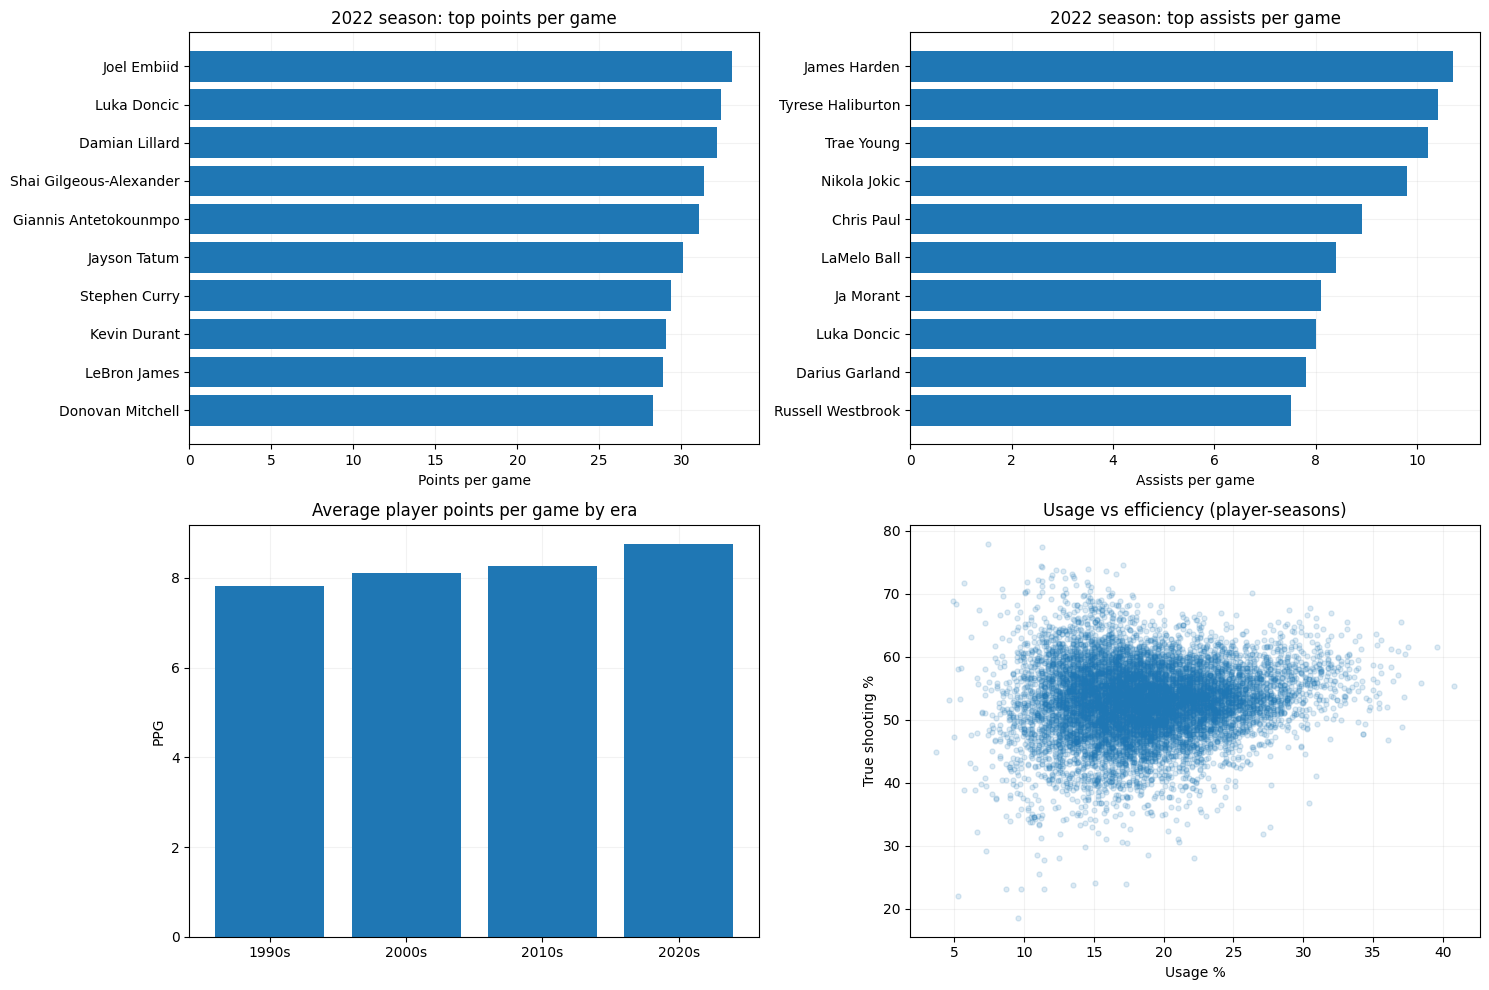

VALIDATION: PASS — distinct player-seasons, rankings, MVP score range and era coverage.
Export files:
 - data_mvp_rankings.csv
 - draft_year_experience_proxy.csv
 - era_comparison.csv
 - nba_executive_dashboard.png
 - player_season_duplicate_keys_AUDIT.csv
 - player_seasons_clean.csv
 - season_top10_leaderboards.csv
 - team_top_performer_frequency.csv
 - usage_vs_efficiency.csv
 - year_over_year_improvement.csv


In [6]:
# CELL 6 — VISUALIZATIONS & RECONCILIATION
fig,ax=plt.subplots(2,2,figsize=(15,10))
for name,axis in [('points',ax[0,0]),('assists',ax[0,1])]:
    sample=leaders[(leaders.season_start==latest)&(leaders.metric==name)&(leaders['rank']<=10)].sort_values('metric_value')
    axis.barh(sample['player'].astype(str),sample['metric_value'])
    axis.set_title(f'{latest} season: top {name} per game');axis.set_xlabel(name.title()+' per game')
if len(by_era):
    ax[1,0].bar(by_era['era'].astype(str),by_era['mean_ppg'])
ax[1,0].set_title('Average player points per game by era');ax[1,0].set_ylabel('PPG')
if len(efficiency):
    ax[1,1].scatter(efficiency['usage_display_pct'],efficiency['ts_display_pct'],alpha=.15,s=13)
    ax[1,1].set_xlabel('Usage %');ax[1,1].set_ylabel('True shooting %')
    ax[1,1].set_title('Usage vs efficiency (player-seasons)')
else: ax[1,1].text(.1,.5,'Efficiency fields unavailable',transform=ax[1,1].transAxes)
for a in ax.flat:a.grid(alpha=.16);a.set_axisbelow(True)
plt.tight_layout()
plt.savefig(SAVE_DIR/'nba_executive_dashboard.png',dpi=170,bbox_inches='tight')
plt.show()

assert valid.groupby(['player','season']).size().max()==1
assert (leaders['rank']<=10).all()
assert (by_era['player_seasons'].sum()<=len(valid))
if len(ranked_mvp):
    assert ranked_mvp['data_mvp_score'].between(0,100).all()
print('VALIDATION: PASS — distinct player-seasons, rankings, MVP score range and era coverage.')
print('Export files:');print('\n'.join(' - '+p.name for p in sorted(SAVE_DIR.iterdir()) if p.is_file()))

In [8]:

# ============================================================
# CELL 7 — FINAL DOCUMENTATION, RECOMMENDATIONS & ZIP
# PROJECT 6: NBA DATA MVP & ERA INTELLIGENCE
# ============================================================

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. SAFE MARKDOWN TABLE FUNCTION
# Fixes Pandas Categorical fillna TypeError
# ------------------------------------------------------------

def mdtable(data, columns, n=10):
    if data is None or len(data) == 0:
        return "Not available from the supplied data."

    table = data.loc[:, columns].head(n).copy()

    # Convert categorical columns before filling missing values.
    for col in table.columns:
        if isinstance(table[col].dtype, pd.CategoricalDtype):
            table[col] = table[col].astype(object)

    # Round numeric columns only.
    numeric_cols = table.select_dtypes(
        include=["number"]
    ).columns

    if len(numeric_cols):
        table[numeric_cols] = table[numeric_cols].round(2)

    # Convert remaining values to display-safe text.
    table = table.astype(object).fillna("—")

    header = "| " + " | ".join(columns) + " |"
    divider = "| " + " | ".join(
        ["---"] * len(columns)
    ) + " |"

    rows = [
        "| " + " | ".join(map(str, row)) + " |"
        for row in table.itertuples(index=False, name=None)
    ]

    return "\n".join([header, divider] + rows)


# ------------------------------------------------------------
# 2. VALIDATE PREVIOUS ANALYSIS
# ------------------------------------------------------------

required_variables = [
    "SAVE_DIR", "raw", "valid", "path",
    "by_era", "ranked_mvp",
    "MIN_GP", "MVP_MIN_GP",
    "excluded_repeated"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

assert not missing_variables, (
    "Missing analysis variables: "
    + str(missing_variables)
    + ". Run earlier notebook cells first."
)

SAVE_DIR = Path(SAVE_DIR)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

assert len(valid) > 0, "No valid player-season rows found."

focus_season = (
    TARGET_SEASON
    if TARGET_SEASON is not None
    else valid.sort_values("season_start")["season"].iloc[-1]
)

latest_mvp = (
    ranked_mvp[
        ranked_mvp["season"] == focus_season
    ].head(10)
    if len(ranked_mvp)
    else pd.DataFrame()
)

pos_present = (
    SAVE_DIR / "dream_starting_five_exploratory.csv"
).exists()

award_present = (
    SAVE_DIR / "data_vs_official_mvp.csv"
).exists()

print("PROJECT 6 — FINAL DOCUMENTATION")
print("=" * 60)
print("Source records:", len(raw))
print("Validated player-season rows:", len(valid))
print("Selected season:", focus_season)
print("Data MVP candidates:", len(latest_mvp))


# ------------------------------------------------------------
# 3. EVIDENCE-BASED BUSINESS RECOMMENDATIONS
# ------------------------------------------------------------

recommendations = f"""# NBA Sports Media — Business Recommendations

## Executive Summary

This project analyzes NBA player-season statistics across
multiple eras to support data-driven sports coverage,
player comparisons, and transparent MVP discussions.

The source contains **{len(raw):,} records**, with
**{len(valid):,} unambiguous player-season records**
included in the main analysis.

The findings are descriptive. Statistical rankings are
not official NBA awards or comprehensive player valuations.

---

## 1. Publish Consistent Season Leaderboards

**Priority: High**

### Evidence
The dataset contains points, rebounds, assists,
games played, true shooting, and usage statistics.

### Actions
- Publish top scorers, rebounders, and playmakers by season.
- Apply the documented {MIN_GP}-game eligibility threshold.
- Show efficiency alongside per-game production.
- Clearly separate per-game rankings from season totals.

### Success Measures
Accurate rankings, consistent eligibility rules,
and transparent editorial reporting.

---

## 2. Evaluate Volume and Efficiency Together

**Priority: High**

### Evidence
The analysis compares usage percentage with
true shooting percentage.

### Actions
- Display usage and efficiency side by side.
- Highlight players with strong production and efficiency.
- Avoid assuming heavy usage causes reduced efficiency.
- Segment analyses by season and player role where possible.

### Success Measures
Clearer player comparisons and fewer misleading
single-stat rankings.

---

## 3. Add Context to Cross-Era Comparisons

**Priority: High**

### Evidence
The dataset supports comparisons across the
1990s, 2000s, 2010s, and 2020s.

### Actions
- Compare average height and weight across eras.
- Track changes in scoring, assists, and true shooting.
- Explain the effects of differing season coverage.
- Avoid treating unadjusted cross-era statistics
  as definitive evidence of overall greatness.

### Success Measures
Consistent era definitions and appropriately
qualified historical comparisons.

---

## 4. Publish a Transparent Data MVP Model

**Priority: High**

### Methodology
The exploratory index combines within-season
percentile rankings:

- 40% points per game
- 15% rebounds per game
- 15% assists per game
- 30% true shooting percentage

The minimum-games threshold is **{MVP_MIN_GP}**
when recorded games are available.

### Actions
- Publish the scoring formula alongside all rankings.
- Explain the criteria and eligibility requirements.
- Compare the Data MVP with official awards only
  when verified award records are available.
- Test whether different weights change the winner.

### Success Measures
Reproducible results and transparent MVP debates.

---

## 5. Compare Team Contributions Fairly

**Priority: Medium**

### Evidence
The analysis identifies teams producing frequent
top-performing player-seasons.

### Actions
- Track each team's top-10 player-season appearances.
- Report rates alongside absolute counts.
- Account for historical team names and season coverage.
- Avoid interpreting individual player production
  as proof of organizational effectiveness.

### Success Measures
Consistent team comparisons with documented denominators.

---

## 6. Improve Player Development Analysis

**Priority: Medium**

### Evidence
Year-over-year changes identify statistical
improvements in scoring, rebounding, and assists.

### Actions
- Track consecutive-season performance changes.
- Add minimum-games thresholds before editorial use.
- Separate increases in playing opportunity
  from improvements in per-minute performance.
- Use draft-year experience only as a proxy,
  not verified NBA rookie status.

### Success Measures
More defensible breakout-player and improvement stories.

---

## 7. Expand Data for Advanced Player Rankings

**Priority: Medium**

### Missing Information
The supplied dataset does not include verified
PG/SG/SF/PF/C positions or official MVP award results.

### Actions
- Add a verified historical player-position mapping.
- Add an authoritative annual MVP winners table.
- Include team wins, minutes, advanced impact metrics,
  and postseason performance where appropriate.
- Reconcile repeated player-season keys.

### Success Measures
A validated Dream Team and official MVP comparison.

---

## Implementation Roadmap

### Immediate
Publish verified season leaderboards and the
exploratory Data MVP results.

### Next 30 Days
Expand efficiency analysis and conduct sensitivity checks.

### Next 60 Days
Add authoritative historical awards and player positions.

### Ongoing
Improve data quality, methodology, and editorial context.

---

## Conclusion

The project provides a transparent statistical framework
for exploring NBA performance and historical trends.

Its rankings support informed sports discussion, but
do not constitute official awards or definitive GOAT results.
"""

(SAVE_DIR / "RECOMMENDATIONS.md").write_text(
    recommendations,
    encoding="utf-8"
)


# ------------------------------------------------------------
# 4. BUILD COMPREHENSIVE README
# ------------------------------------------------------------

mvp_columns = [
    "player", "season", "team", "games",
    "points", "rebounds", "assists",
    "ts_display_pct", "data_mvp_score"
]

era_columns = [
    "era", "player_seasons",
    "mean_height", "mean_weight",
    "mean_ppg", "mean_rpg",
    "mean_apg", "mean_ts_pct"
]

mvp_table = mdtable(
    latest_mvp,
    mvp_columns,
    10
)

era_table = mdtable(
    by_era,
    era_columns,
    10
)

readme = f"""# NBA Player Analytics — Era Intelligence & Data MVP

![NBA Executive Dashboard](nba_executive_dashboard.png)

## Project Overview

This sports analytics project explores NBA player
performance across multiple seasons, comparing:

- Scoring, rebounding, and playmaking
- Usage rate and shooting efficiency
- Statistical improvements across seasons
- Historical eras and player physical characteristics
- Team contributions to elite performance
- Draft-year experience categories
- Exploratory Data MVP rankings

The project was developed using Python and Google Colab.

## Business Objective

Help a sports media company create data-driven
NBA player comparisons, historical insights,
and reproducible MVP discussions.

## Dataset Overview

| Metric | Value |
|---|---|
| Source file | `{path.name}` |
| Original records | {len(raw):,} |
| Analyzed player-season records | {len(valid):,} |
| Excluded repeated-key records | {excluded_repeated:,} |
| Earliest season start | {int(valid["season_start"].min())} |
| Latest season start | {int(valid["season_start"].max())} |
| Season leaderboards minimum games | {MIN_GP} |
| Data MVP minimum games | {MVP_MIN_GP} |

The original dataset was supplied for this exercise.
Its statistics have not been independently reconciled
with official NBA records.

## Data Preparation

The notebook:

1. Loads the original dataset.
2. Inspects missing values and duplicate records.
3. Standardizes statistical columns.
4. Identifies season years and historical eras.
5. Excludes ambiguous repeated player-season keys.
6. Calculates rankings and efficiency measures.
7. Produces CSV exports and visualizations.
8. Validates the main analytical outputs.

## Season Performance Analysis

Players are ranked by:

- Points per game
- Rebounds per game
- Assists per game

Leaderboards apply a minimum-games threshold
to reduce the influence of very small samples.

See `season_top10_leaderboards.csv`.

## Volume Versus Efficiency

The analysis compares:

- Usage percentage
- True shooting percentage

The relationship is descriptive, not causal.

High usage does not necessarily mean low efficiency.

See `usage_vs_efficiency.csv`.

## Most Improved Players

The improvement index combines changes in:

- Points per game
- Rebounds per game
- Assists per game

Only consecutive recorded seasons are compared.

Because the index adds metrics with different units,
it is an exploratory measure rather than an official award.

See `year_over_year_improvement.csv`.

## Era Comparison

The dataset groups seasons into four eras:

- 1990s
- 2000s
- 2010s
- 2020s

### Era Summary

{era_table}

Height and weight describe recorded player-season
averages. Performance comparisons are not adjusted
for pace, minutes, rule changes, or competition.

## Team Comparison

The team analysis measures how often franchises
appear among top-ranked player-seasons.

Both raw frequencies and rates are useful,
because teams have different coverage periods.

See `team_top_performer_frequency.csv`.

## Rookie Versus Veteran Analysis

Draft year is used to estimate years since draft.

This is not identical to actual NBA experience.

Groups include:

- Draft-year entrants
- Players at least five years after draft
- Other or unknown experience categories

See `draft_year_experience_proxy.csv`.

## Data MVP Methodology

The Data MVP is an exploratory score calculated
from within-season statistical percentile rankings.

| Component | Weight |
|---|---:|
| Points per game | 40% |
| Rebounds per game | 15% |
| Assists per game | 15% |
| True shooting percentage | 30% |
| **Total** | **100%** |

These weights express one transparent editorial
definition of statistical performance.

The model does not directly incorporate:
defensive impact, team success, playoff results,
or the full context used in official MVP voting.

## Selected Season: {focus_season}

### Top Data MVP Candidates

{mvp_table}

See `data_mvp_rankings.csv` for additional rankings.

## Executive Visualization

The project includes:

`nba_executive_dashboard.png`

The dashboard provides a static overview
of the available NBA statistics.

## Data Validation

The analysis checks:

- Required player and season fields
- Ambiguous repeated player-season keys
- Season rankings
- Era coverage
- MVP score ranges
- Available statistical measures

Excluded or ambiguous records are not silently
averaged into fabricated player-season statistics.

See `player_season_duplicate_keys_AUDIT.csv`
when duplicate keys are present.

## Business Recommendations

See [RECOMMENDATIONS.md](RECOMMENDATIONS.md).

The document contains seven evidence-based
editorial and analytics recommendations.

## Main Project Files

| File | Purpose |
|---|---|
| `season_top10_leaderboards.csv` | Seasonal statistical leaders |
| `year_over_year_improvement.csv` | Player improvements |
| `era_comparison.csv` | Historical era statistics |
| `team_top_performer_frequency.csv` | Elite player-season frequency |
| `draft_year_experience_proxy.csv` | Experience-category analysis |
| `usage_vs_efficiency.csv` | Usage and shooting data |
| `data_mvp_rankings.csv` | Exploratory MVP rankings |
| `player_seasons_clean.csv` | Analyzed player-season records |
| `nba_executive_dashboard.png` | Static executive dashboard |
| `RECOMMENDATIONS.md` | Business recommendations |
| `requirements.txt` | Python dependencies |

## Optional Features

**Official MVP comparison:**
{"Included from verified supplementary data." if award_present else "Not included because a verified official MVP awards dataset was not supplied."}

**PG/SG/SF/PF/C Dream Team:**
{"Exploratory lineup included from supplementary position data." if pos_present else "Not included because verified player positions were not supplied."}

These results must not be invented from incomplete data.

## Tools and Technologies

- Python
- pandas
- NumPy
- Matplotlib
- Google Colab
- CSV

## How to Reproduce

1. Open `NBA_Project6_Data_MVP_Analysis.ipynb`
   in Google Colab.
2. Upload the original NBA dataset.
3. If needed, set `DATA_FILE` to the exact file path.
4. Run the notebook cells in order.
5. Review validation results.
6. Find outputs in `/content/NBA_Project6_Outputs`.
7. Download the ZIP package and notebook.

## Limitations

- NBA seasons are only covered where present
  in the supplied dataset.
- Cross-era statistics are not pace-adjusted.
- Position-specific rankings require position data.
- Official MVP comparisons require verified award data.
- Draft-year experience is a proxy.
- Repeated player-season records are excluded
  rather than arbitrarily combined.
- Different MVP weights may change the winner.
- Statistical rankings do not define overall greatness.

## Future Improvements

- Official MVP award comparison
- Verified position-based Dream Team
- More advanced impact metrics
- Pace-adjusted historical comparisons
- Games-played sensitivity analysis
- Team wins and playoff performance

## GitHub Publication

**Repository name:**
`NBA-Player-Era-Data-MVP-Analytics`

**Suggested description:**

NBA player-season analytics exploring era trends,
performance leaders, efficiency, and a transparent
Data MVP model.

Create the GitHub repository:

https://github.com/new

Upload the project files and notebook,
verify the repository, then STOP.
"""

(SAVE_DIR / "README.md").write_text(
    readme,
    encoding="utf-8"
)


# ------------------------------------------------------------
# 5. REQUIREMENTS AND GITIGNORE
# ------------------------------------------------------------

requirements = """pandas>=2.0,<4.0
numpy>=1.24,<3.0
matplotlib>=3.7,<4.0
openpyxl>=3.1
pyarrow>=12
"""

(SAVE_DIR / "requirements.txt").write_text(
    requirements,
    encoding="utf-8"
)

gitignore = """.ipynb_checkpoints/
__pycache__/
.DS_Store
.venv/
"""

(SAVE_DIR / ".gitignore").write_text(
    gitignore,
    encoding="utf-8"
)


# ------------------------------------------------------------
# 6. VERIFY REQUIRED FILES
# ------------------------------------------------------------

required_files = [
    "README.md",
    "RECOMMENDATIONS.md",
    "requirements.txt",
    ".gitignore",
    "nba_executive_dashboard.png",
    "player_seasons_clean.csv",
    "season_top10_leaderboards.csv",
    "year_over_year_improvement.csv",
    "era_comparison.csv",
    "team_top_performer_frequency.csv",
    "draft_year_experience_proxy.csv",
    "usage_vs_efficiency.csv",
    "data_mvp_rankings.csv"
]

missing_files = [
    filename
    for filename in required_files
    if not (SAVE_DIR / filename).is_file()
]

assert not missing_files, (
    "Missing required files: "
    + ", ".join(missing_files)
)

print("\nFILE VALIDATION: PASS")
print("All required outputs are present.")


# ------------------------------------------------------------
# 7. CREATE COMPLETE PROJECT ZIP
# ------------------------------------------------------------

zip_path = Path(
    "/content/NBA_Project6_Portfolio_Package.zip"
)

project_files = sorted(
    f for f in SAVE_DIR.iterdir()
    if f.is_file()
)

with ZipFile(
    zip_path,
    "w",
    compression=ZIP_DEFLATED
) as archive:

    for project_file in project_files:
        archive.write(
            project_file,
            arcname=project_file.name
        )

# Verify ZIP integrity and required entries.
with ZipFile(zip_path, "r") as archive:
    assert archive.testzip() is None, (
        "ZIP integrity check failed."
    )

    zip_names = set(archive.namelist())

    assert set(required_files).issubset(zip_names), (
        "Required files are missing from the ZIP."
    )


# ------------------------------------------------------------
# 8. FINAL CONFIRMATION AND DOWNLOAD
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PROJECT 6 — FINAL PACKAGE")
print("=" * 60)

print("README: CREATED")
print("RECOMMENDATIONS: CREATED")
print("DEPENDENCIES: CREATED")
print("DASHBOARD: INCLUDED")
print("CSV EXPORTS: INCLUDED")
print("ZIP INTEGRITY: PASS")

print("Files packaged:", len(project_files))
print("Package:", zip_path.name)

print("\nPACKAGE READY")
print("\nNOTEBOOK: Download separately as .ipynb")
print("DATASET:", path.name)
print("Original dataset is not duplicated in the ZIP.")

from google.colab import files

files.download(str(zip_path))


PROJECT 6 — FINAL DOCUMENTATION
Source records: 12844
Validated player-season rows: 12836
Selected season: 2022-23
Data MVP candidates: 10

FILE VALIDATION: PASS
All required outputs are present.


/tmp/ipykernel_577/919728275.py:36: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  table = table.astype(object).fillna("—")
/tmp/ipykernel_577/919728275.py:36: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  table = table.astype(object).fillna("—")



PROJECT 6 — FINAL PACKAGE
README: CREATED
RECOMMENDATIONS: CREATED
DEPENDENCIES: CREATED
DASHBOARD: INCLUDED
CSV EXPORTS: INCLUDED
ZIP INTEGRITY: PASS
Files packaged: 14
Package: NBA_Project6_Portfolio_Package.zip

PACKAGE READY

NOTEBOOK: Download separately as .ipynb
DATASET: all_seasons.csv
Original dataset is not duplicated in the ZIP.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>